In [3]:
import pandas as pd

# Load the comma-separated dataset
df = pd.read_csv("/content/bank.csv", sep=",")

# Clean column names
df.columns = df.columns.str.strip()

# Inspect the dataset
print("Dataset shape:", df.shape)
display(df.head())
df.info()

Dataset shape: (11162, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        11162 non-null  int64 
 1   job        11162 non-null  object
 2   marital    11162 non-null  object
 3   education  11162 non-null  object
 4   default    11162 non-null  object
 5   balance    11162 non-null  int64 
 6   housing    11162 non-null  object
 7   loan       11162 non-null  object
 8   contact    11162 non-null  object
 9   day        11162 non-null  int64 
 10  month      11162 non-null  object
 11  duration   11162 non-null  int64 
 12  campaign   11162 non-null  int64 
 13  pdays      11162 non-null  int64 
 14  previous   11162 non-null  int64 
 15  poutcome   11162 non-null  object
 16  deposit    11162 non-null  object
dtypes: int64(7), object(10)
memory usage: 1.4+ MB


In [4]:
# Check the target and create samples

from sklearn.model_selection import train_test_split

# Check the target distribution
print("Target counts:")
print(df["deposit"].value_counts())

print("\nTarget percentages:")
print(
    df["deposit"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

# Create development and holdout samples
development_df, holdout_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df["deposit"],
    random_state=42
)

print("\nDevelopment sample shape:", development_df.shape)
print("Holdout sample shape:", holdout_df.shape)

Target counts:
deposit
no     5873
yes    5289
Name: count, dtype: int64

Target percentages:
deposit
no     52.62
yes    47.38
Name: proportion, dtype: float64

Development sample shape: (8929, 17)
Holdout sample shape: (2233, 17)


In [5]:
# Begin the SEMMA Explore phase
# Basic data-quality exploration

print("Development sample shape:", development_df.shape)

print("\nColumn data types:")
display(development_df.dtypes)

print("\nMissing values by column:")
display(development_df.isnull().sum().sort_values(ascending=False))

print("\nNumber of duplicate rows:")
print(development_df.duplicated().sum())

print("\nNumerical summary:")
display(development_df.describe().T)

Development sample shape: (8929, 17)

Column data types:


,0
age,int64
job,object
marital,object
education,object
default,object
balance,int64
housing,object
loan,object
contact,object
day,int64



Missing values by column:


,0
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0



Number of duplicate rows:
0

Numerical summary:


,count,mean,std,min,25%,50%,75%,max
age,8929.0,41.106731,11.876074,18.0,32.0,39.0,49.0,95.0
balance,8929.0,1482.312577,2975.334928,-6847.0,122.0,552.0,1694.0,81204.0
day,8929.0,15.683503,8.429058,1.0,8.0,15.0,22.0,31.0
duration,8929.0,369.998320,345.956932,2.0,137.0,253.0,492.0,3284.0
campaign,8929.0,2.503192,2.783684,1.0,1.0,2.0,3.0,63.0
pdays,8929.0,51.794490,109.077260,-1.0,-1.0,-1.0,38.0,854.0
previous,8929.0,0.829768,2.331394,0.0,0.0,0.0,1.0,58.0


Target counts:
deposit
no     4698
yes    4231
Name: count, dtype: int64

Target percentages:
deposit
no     52.62
yes    47.38
Name: proportion, dtype: float64


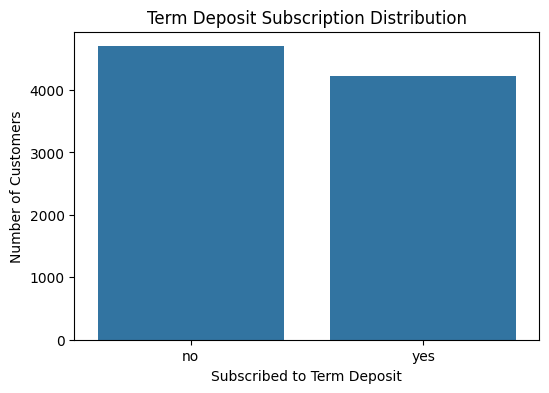

In [6]:
#Target Distribution

import matplotlib.pyplot as plt
import seaborn as sns

# Count and percentage of each target class
target_counts = development_df["deposit"].value_counts()
target_percentages = (
    development_df["deposit"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("Target counts:")
print(target_counts)

print("\nTarget percentages:")
print(target_percentages)

# Plot the target distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=development_df, x="deposit")

plt.title("Term Deposit Subscription Distribution")
plt.xlabel("Subscribed to Term Deposit")
plt.ylabel("Number of Customers")
plt.show()

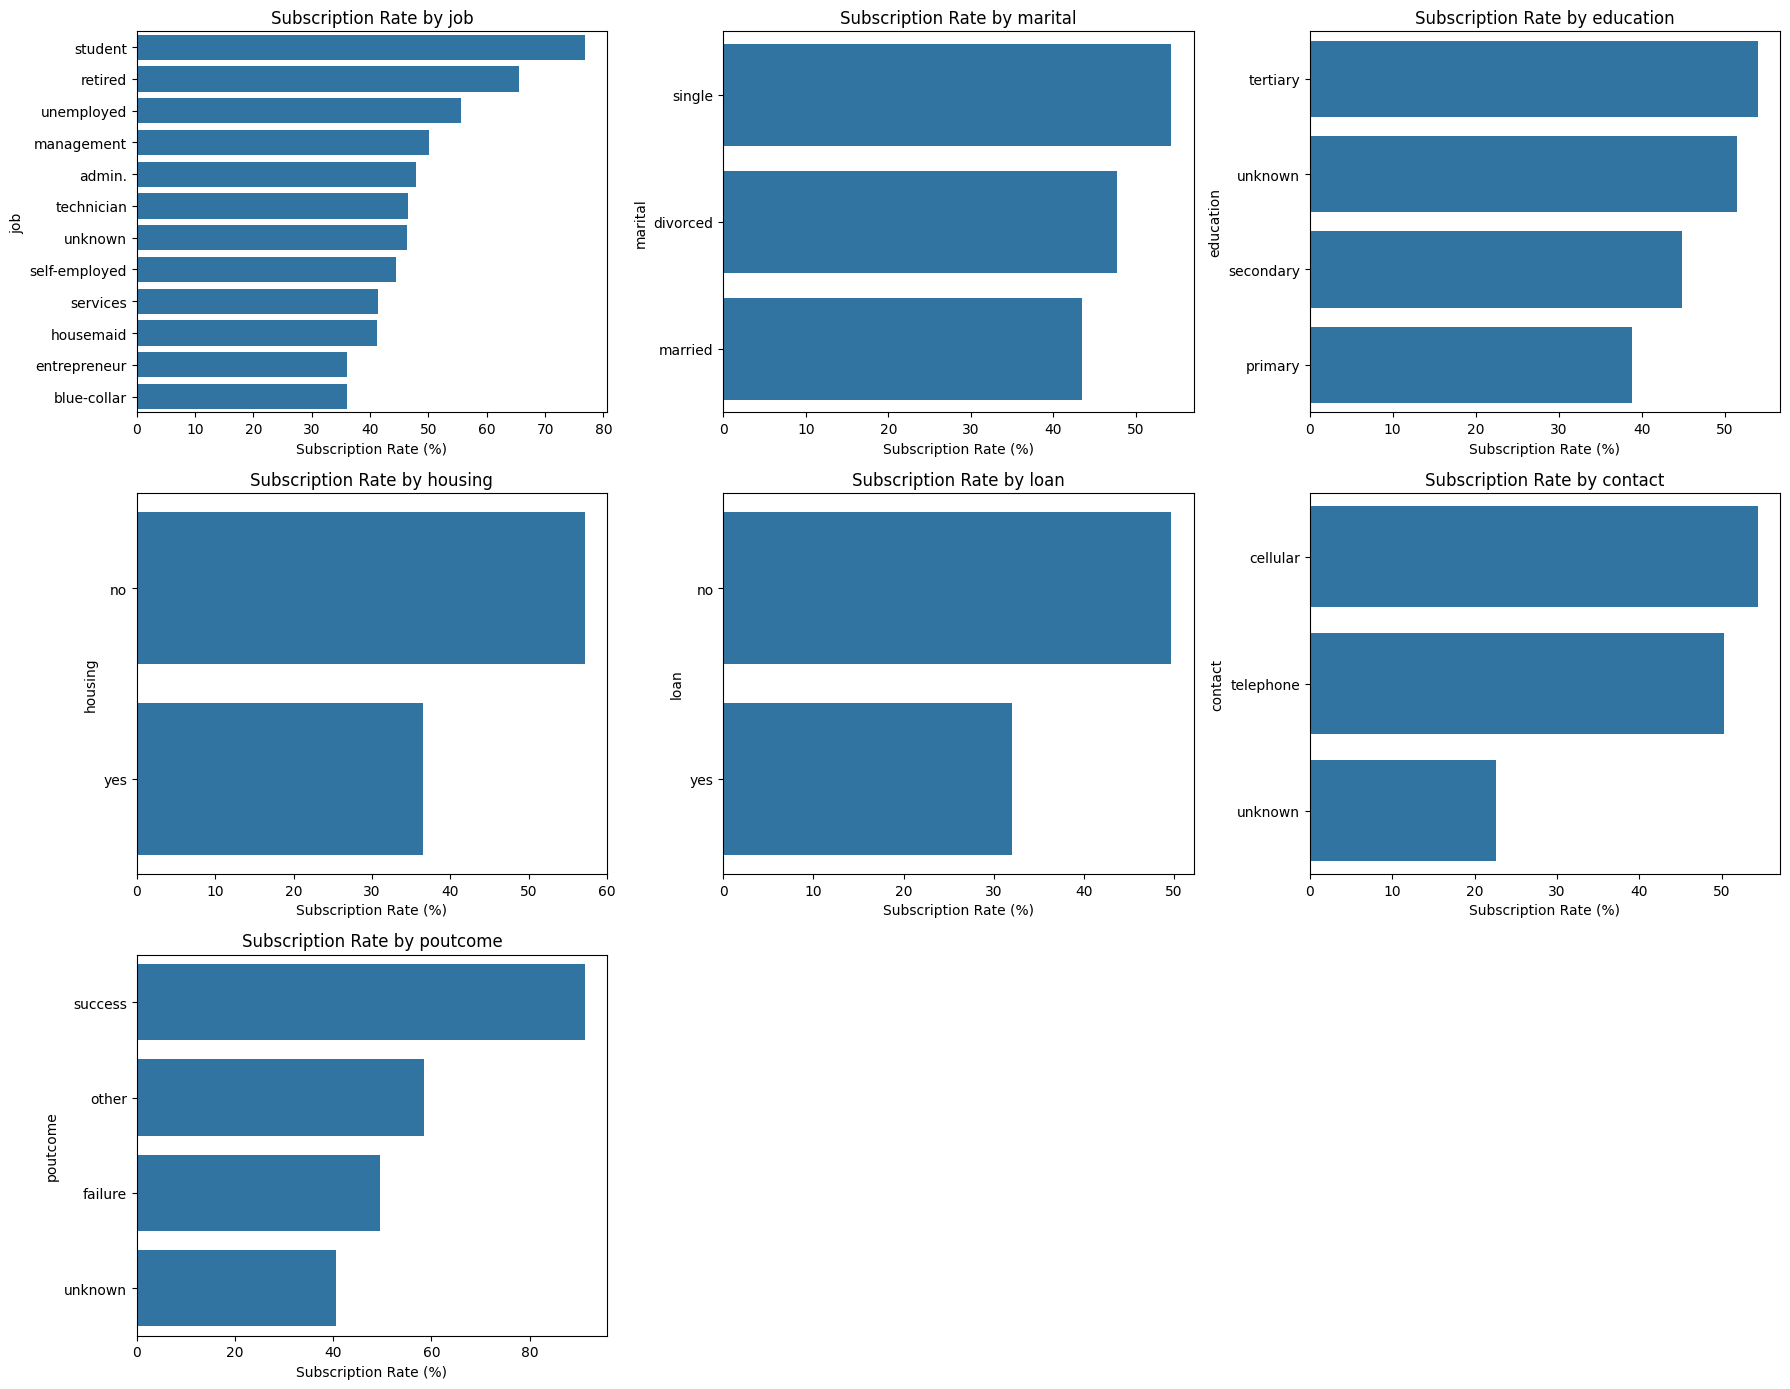

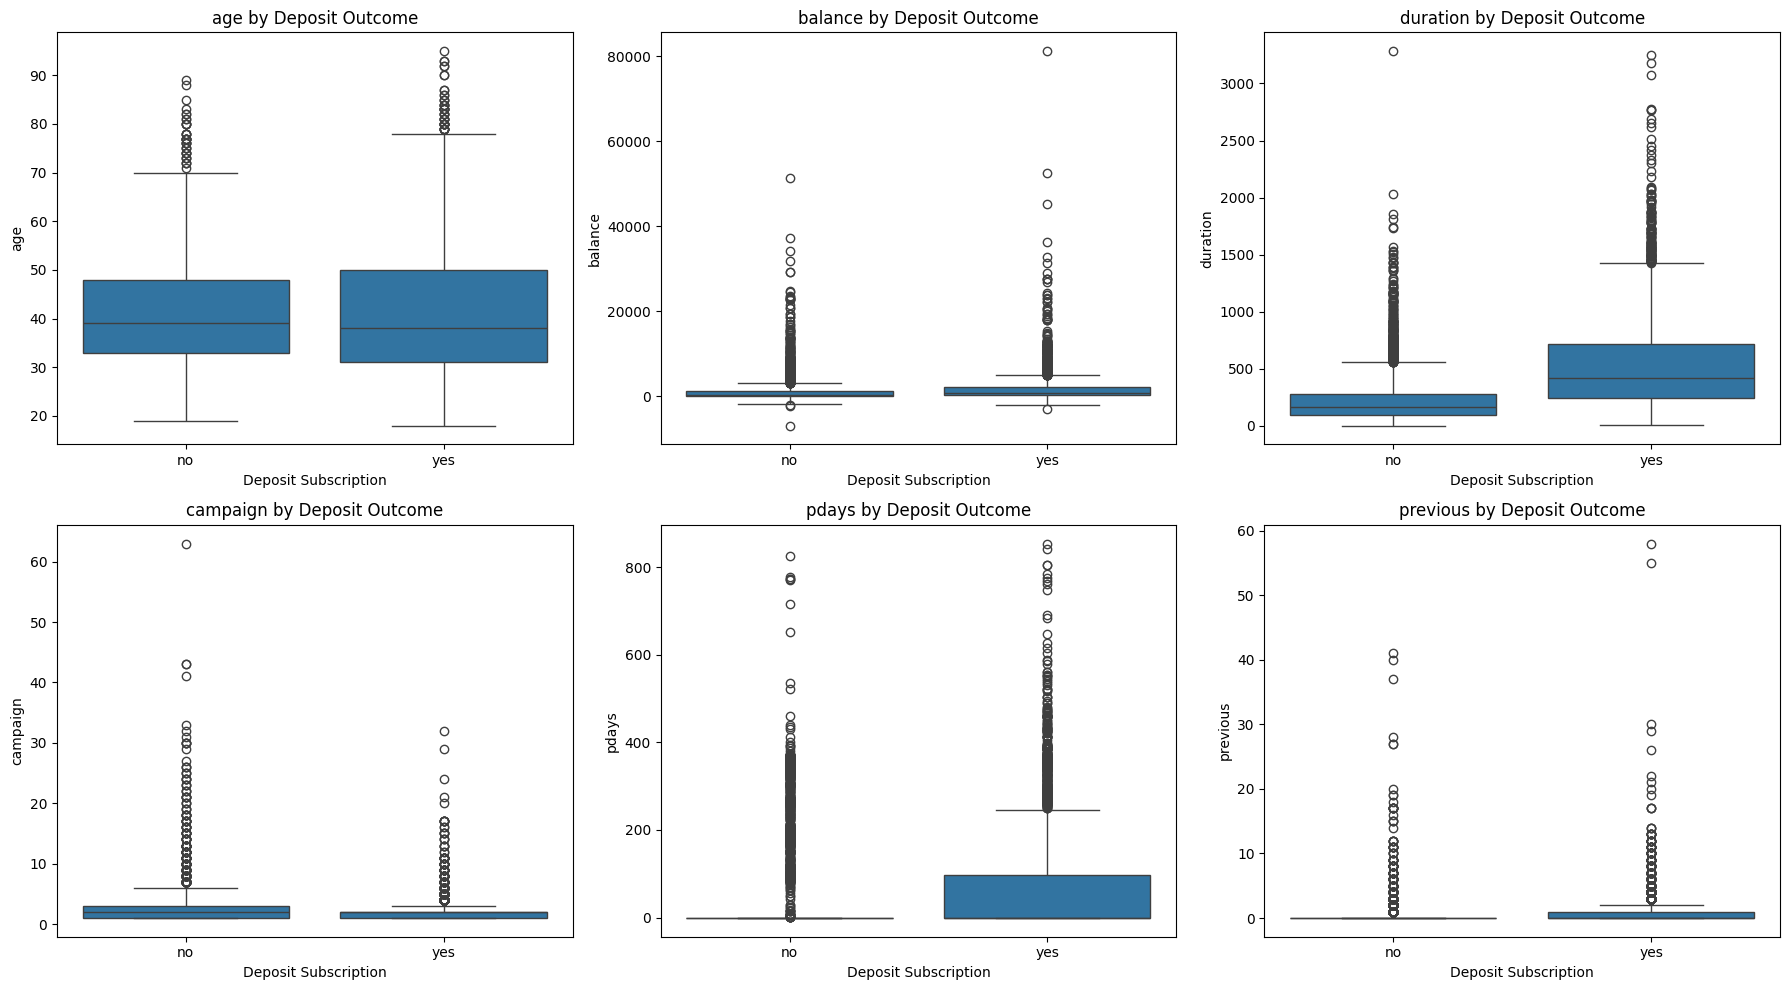

In [8]:
#Compare subscription rates by category

import matplotlib.pyplot as plt
import seaborn as sns

# Create a numeric version of the target for calculating subscription rates
explore_df = development_df.copy()
explore_df["subscribed"] = (explore_df["deposit"] == "yes").astype(int)

categorical_features = [
    "job",
    "marital",
    "education",
    "housing",
    "loan",
    "contact",
    "poutcome"
]

fig, axes = plt.subplots(3, 3, figsize=(18, 14))
axes = axes.flatten()

for i, feature in enumerate(categorical_features):
    subscription_rate = (
        explore_df.groupby(feature)["subscribed"]
        .mean()
        .sort_values(ascending=False)
        .mul(100)
    )

    sns.barplot(
        x=subscription_rate.values,
        y=subscription_rate.index,
        ax=axes[i]
    )

    axes[i].set_title(f"Subscription Rate by {feature}")
    axes[i].set_xlabel("Subscription Rate (%)")
    axes[i].set_ylabel(feature)

# Hide unused plots
for i in range(len(categorical_features), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()

numeric_features = [
    "age",
    "balance",
    "duration",
    "campaign",
    "pdays",
    "previous"
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, feature in enumerate(numeric_features):
    sns.boxplot(
        data=development_df,
        x="deposit",
        y=feature,
        ax=axes[i]
    )

    axes[i].set_title(f"{feature} by Deposit Outcome")
    axes[i].set_xlabel("Deposit Subscription")
    axes[i].set_ylabel(feature)

plt.tight_layout()
plt.show()

In [9]:
# SEMMA Modify phase

# Create copies for modification
development_modified = development_df.copy()
holdout_modified = holdout_df.copy()

# Convert the target into binary values
development_modified["deposit"] = (
    development_modified["deposit"] == "yes"
).astype(int)

holdout_modified["deposit"] = (
    holdout_modified["deposit"] == "yes"
).astype(int)

# Separate predictors and target
X_development = development_modified.drop(columns=["deposit"])
y_development = development_modified["deposit"]

X_holdout = holdout_modified.drop(columns=["deposit"])
y_holdout = holdout_modified["deposit"]

# Identify feature types
categorical_features = X_development.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_features = X_development.select_dtypes(
    exclude=["object"]
).columns.tolist()

print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

print("\nDevelopment features shape:", X_development.shape)
print("Holdout features shape:", X_holdout.shape)

Categorical features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Numerical features:
['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']

Development features shape: (8929, 16)
Holdout features shape: (2233, 16)


In [10]:
# encoding and scaling step of SEMMA

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Create the preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            StandardScaler(),
            numerical_features
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ]
)

# Fit only on the development sample
X_development_prepared = preprocessor.fit_transform(X_development)

# Apply the same transformation to the holdout sample
X_holdout_prepared = preprocessor.transform(X_holdout)

print("Prepared development shape:", X_development_prepared.shape)
print("Prepared holdout shape:", X_holdout_prepared.shape)

Prepared development shape: (8929, 51)
Prepared holdout shape: (2233, 51)


In [11]:
# SEMMA Model phase

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Define models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=6,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )
}

# Train each model
for model_name, model in models.items():
    model.fit(
        X_development_prepared,
        y_development
    )
    print(f"{model_name} trained successfully.")

Logistic Regression trained successfully.
Decision Tree trained successfully.
Random Forest trained successfully.


In [12]:
# Model assessment

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

assessment_results = []
model_predictions = {}

for model_name, model in models.items():
    # Generate predictions
    y_pred = model.predict(X_holdout_prepared)
    y_prob = model.predict_proba(X_holdout_prepared)[:, 1]

    # Save predictions for later charts
    model_predictions[model_name] = {
        "predicted_class": y_pred,
        "predicted_probability": y_prob
    }

    # Calculate metrics
    assessment_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_holdout, y_pred),
        "Precision": precision_score(y_holdout, y_pred),
        "Recall": recall_score(y_holdout, y_pred),
        "F1-score": f1_score(y_holdout, y_pred),
        "ROC-AUC": roc_auc_score(y_holdout, y_prob)
    })

    print(f"\n{model_name}")
    print(classification_report(y_holdout, y_pred))

# Create comparison table
assessment_df = pd.DataFrame(assessment_results)
assessment_df = assessment_df.sort_values(
    by="F1-score",
    ascending=False
)

display(assessment_df.round(3))


Logistic Regression
              precision    recall  f1-score   support

           0       0.82      0.85      0.84      1175
           1       0.83      0.80      0.81      1058

    accuracy                           0.83      2233
   macro avg       0.83      0.82      0.83      2233
weighted avg       0.83      0.83      0.83      2233


Decision Tree
              precision    recall  f1-score   support

           0       0.81      0.83      0.82      1175
           1       0.81      0.79      0.80      1058

    accuracy                           0.81      2233
   macro avg       0.81      0.81      0.81      2233
weighted avg       0.81      0.81      0.81      2233


Random Forest
              precision    recall  f1-score   support

           0       0.89      0.83      0.86      1175
           1       0.83      0.89      0.86      1058

    accuracy                           0.86      2233
   macro avg       0.86      0.86      0.86      2233
weighted avg       0.86

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
2,Random Forest,0.858,0.825,0.888,0.855,0.920
0,Logistic Regression,0.826,0.828,0.800,0.813,0.907
1,Decision Tree,0.811,0.809,0.786,0.798,0.880


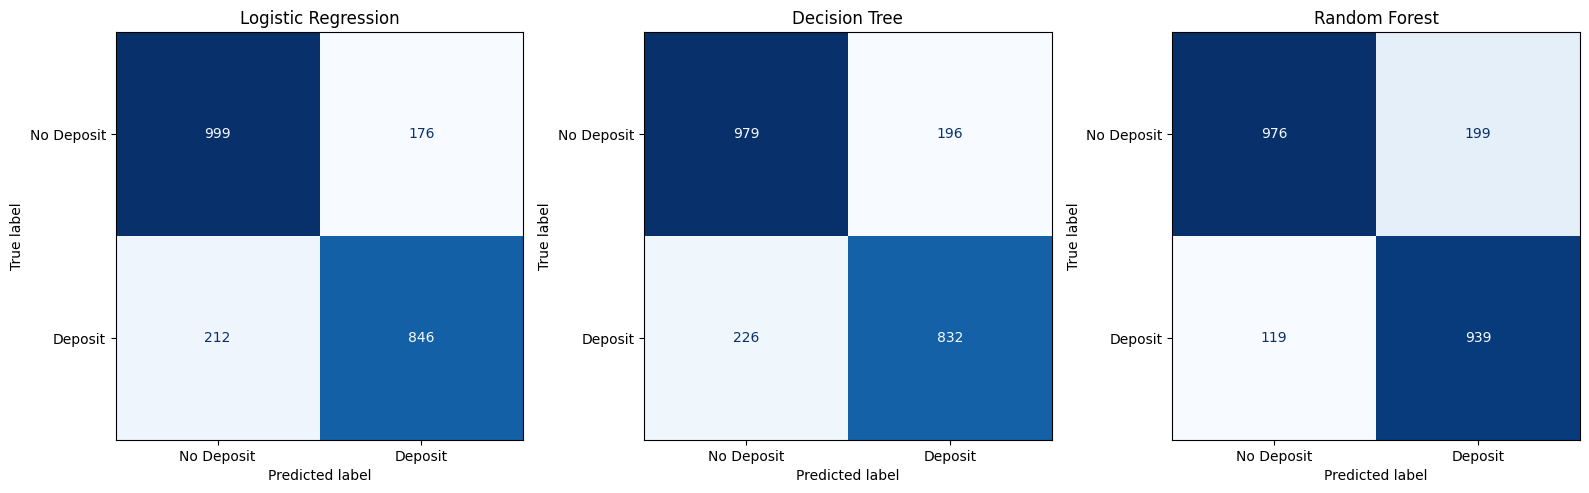

In [13]:
# Confusion Matrix

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for axis, (model_name, predictions) in zip(
    axes,
    model_predictions.items()
):
    ConfusionMatrixDisplay.from_predictions(
        y_holdout,
        predictions["predicted_class"],
        display_labels=["No Deposit", "Deposit"],
        cmap="Blues",
        colorbar=False,
        ax=axis
    )

    axis.set_title(model_name)

plt.tight_layout()
plt.show()

In [14]:
# save the selected model and preprocessing pipeline

import os
import joblib

# Create a models folder in Colab
os.makedirs("/content/models", exist_ok=True)

# Save the selected Random Forest model
joblib.dump(
    models["Random Forest"],
    "/content/models/semma_bank_random_forest.joblib"
)

# Save the preprocessing pipeline
joblib.dump(
    preprocessor,
    "/content/models/semma_bank_preprocessor.joblib"
)

# Save deployment information
deployment_config = {
    "target_column": "deposit",
    "positive_class": 1,
    "model_name": "Random Forest"
}

joblib.dump(
    deployment_config,
    "/content/models/semma_deployment_config.joblib"
)

print("Model artifacts saved:")
print(os.listdir("/content/models"))

Model artifacts saved:
['semma_bank_random_forest.joblib', 'semma_bank_preprocessor.joblib', 'semma_deployment_config.joblib']


In [16]:
# Save models
from google.colab import files

files.download("/content/models/semma_bank_random_forest.joblib")
files.download("/content/models/semma_bank_preprocessor.joblib")
files.download("/content/models/semma_deployment_config.joblib")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>